<center><img src="redpopcorn.jpg"></center>

**Netflix**! What started in 1997 as a DVD rental service has since exploded into one of the largest entertainment and media companies.

Given the large number of movies and series available on the platform, it is a perfect opportunity to flex your exploratory data analysis skills and dive into the entertainment industry.

You work for a production company that specializes in nostalgic styles. You want to do some research on movies released in the 1990's. You'll delve into Netflix data and perform exploratory data analysis to better understand this awesome movie decade!

You have been supplied with the dataset `netflix_data.csv`, along with the following table detailing the column names and descriptions. Feel free to experiment further after submitting!

## The data
### **netflix_data.csv**
| Column | Description |
|--------|-------------|
| `show_id` | The ID of the show |
| `type` | Type of show |
| `title` | Title of the show |
| `director` | Director of the show |
| `cast` | Cast of the show |
| `country` | Country of origin |
| `date_added` | Date added to Netflix |
| `release_year` | Year of Netflix release |
| `duration` | Duration of the show in minutes |
| `description` | Description of the show |
| `genre` | Show genre |

In [44]:
# Importing pandas and matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Read in the Netflix CSV as a DataFrame
netflix_df = pd.read_csv("netflix_data.csv")

In [45]:
# print(netflix_df.sample(10))

# Selecting Movies from the Netflix Record ----------------------

movies_df = netflix_df.loc[netflix_df["type"] == "Movie", ["title","type",
                                                           "duration", "release_year", "genre"]]
# print(movies_df)


In [46]:
# Ensure 'release_year' is integer type
movies_df["release_year"] = pd.to_numeric(movies_df["release_year"], errors='coerce')

# Filter for movies released in the 1990s (1990-1999)
movies1990_df = movies_df.loc[
    (movies_df["release_year"] >= 1990) & (movies_df["release_year"] < 2000),
    ["title", "duration", "genre", "release_year"]]

print(movies1990_df)

                                title  duration           genre  release_year
6                                 187       119          Dramas          1997
118                 A Dangerous Woman       101          Dramas          1993
145            A Night at the Roxbury        82        Comedies          1998
167   A Thin Line Between Love & Hate       108        Comedies          1996
194                      Aashik Awara       154          Dramas          1993
...                               ...       ...             ...           ...
4672                      West Beirut       106          Dramas          1999
4689      What's Eating Gilbert Grape       118  Classic Movies          1993
4718                   Wild Wild West       106          Action          1999
4746                       Wyatt Earp       191          Action          1994
4756                      Yaar Gaddar       148          Dramas          1994

[183 rows x 4 columns]


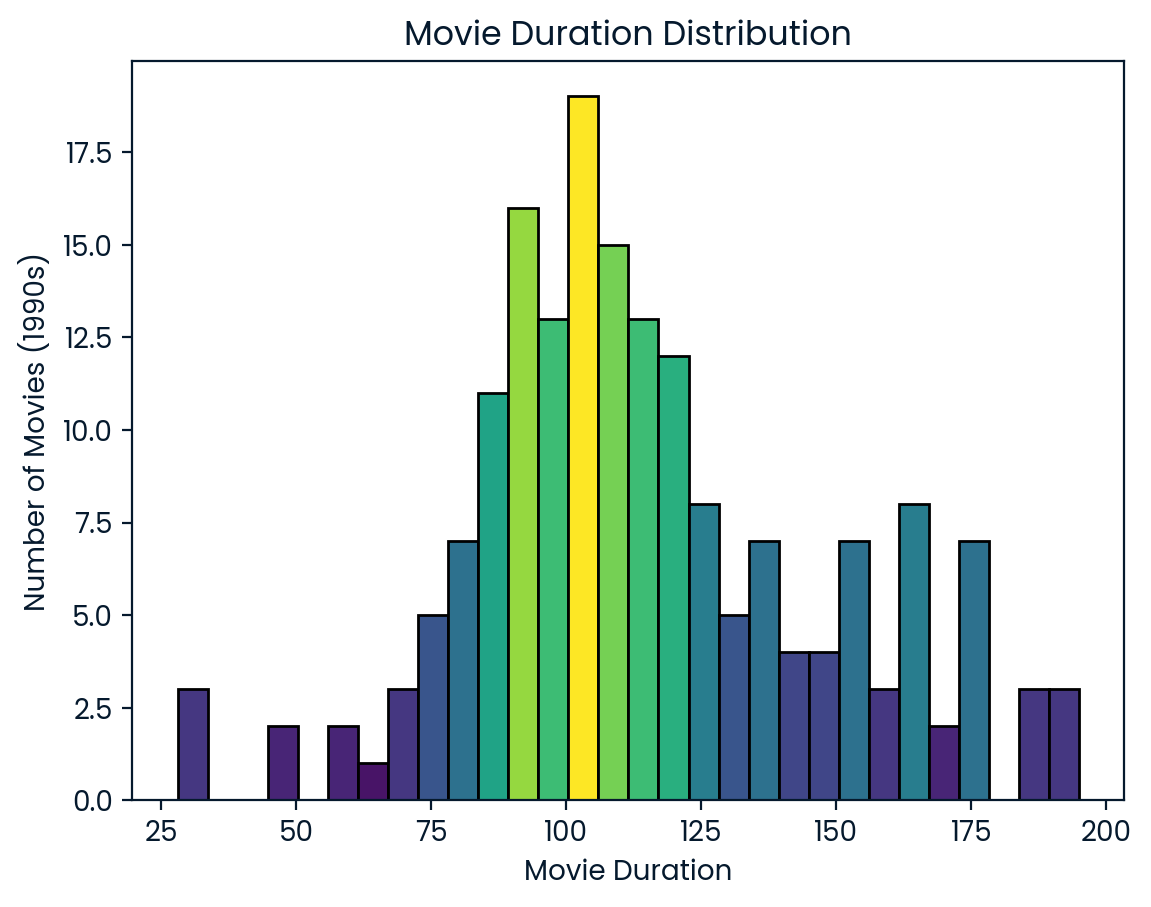

In [47]:
duration = int(movies1990_df["duration"].mode()[0])

duration_values = movies1990_df["duration"]

# Compute histogram data
counts, bins, patches = plt.hist(duration_values, bins=30, edgecolor='black')

# Normalize counts for colormap
norm = plt.Normalize(counts.min(), counts.max())
cmap = plt.cm.viridis

# Color each bar according to its height (darker in the middle where counts are higher)
for count, patch in zip(counts, patches):
    color = cmap(norm(count))
    patch.set_facecolor(color)

plt.title("Movie Duration Distribution")
plt.xlabel("Movie Duration")
plt.ylabel("Number of Movies (1990s)")
plt.show()


In [48]:
action_movies = movies1990_df[(movies1990_df["genre"] == "Action")]

#print(action_movies)

short_movie_count = (action_movies["duration"] < 90).sum()


print(short_movie_count)



7
